# лабораторная работа 2

## построение карты по спутниковому снимку

## настройки и импорты

In [1]:
from pathlib import Path
from copy import deepcopy
import random
import tarfile

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as f
from torch.utils.data import Dataset, DataLoader

random.seed(7)
np.random.seed(7)
torch.manual_seed(7)
torch.set_num_threads(min(4, torch.get_num_threads()))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
image_size = 128
train_limit = 450
val_limit = 40
batch_size = 8
epochs = 35
learning_rate = 0.0005
road_threshold = 245

result_dir = Path("results_roads")
result_dir.mkdir(exist_ok=True)

print("устройство", device)

устройство cpu


## подготовка изображений

In [2]:
data_dir = Path("data") / "maps"
archive = Path("data") / "maps.tar.gz"

train_dir = data_dir / "train"
val_dir = data_dir / "val"
train_dir.mkdir(parents=True, exist_ok=True)
val_dir.mkdir(parents=True, exist_ok=True)

if archive.exists():
    if not tarfile.is_tarfile(archive):
        raise ValueError("архив maps.tar.gz не читается")

    with tarfile.open(archive, "r:*") as files:
        groups = {"train": [], "val": []}
        for item in files.getmembers():
            if not item.isfile() or not item.name.lower().endswith(".jpg"):
                continue
            parts = Path(item.name).parts
            for split in groups:
                if split in parts:
                    groups[split].append(item)
                    break

        rng = random.Random(7)
        for split, folder, limit in (
            ("train", train_dir, train_limit),
            ("val", val_dir, val_limit)
        ):
            items = groups[split]
            rng.shuffle(items)
            for item in items[:limit]:
                destination = folder / Path(item.name).name
                if destination.exists():
                    continue
                source = files.extractfile(item)
                if source is None:
                    continue
                with source, open(destination, "wb") as target:
                    target.write(source.read())
else:
    print("архив не найден, используем изображения из data/maps")

rng = random.Random(7)
train_files = sorted(train_dir.glob("*.jpg"))
val_files = sorted(val_dir.glob("*.jpg"))
rng.shuffle(train_files)
rng.shuffle(val_files)
train_files = train_files[:train_limit]
val_files = val_files[:val_limit]

if not train_files or not val_files:
    raise RuntimeError("не найдены изображения для обучения и проверки")

print("изображений для обучения", len(train_files))
print("изображений для проверки", len(val_files))

изображений для обучения 450
изображений для проверки 40


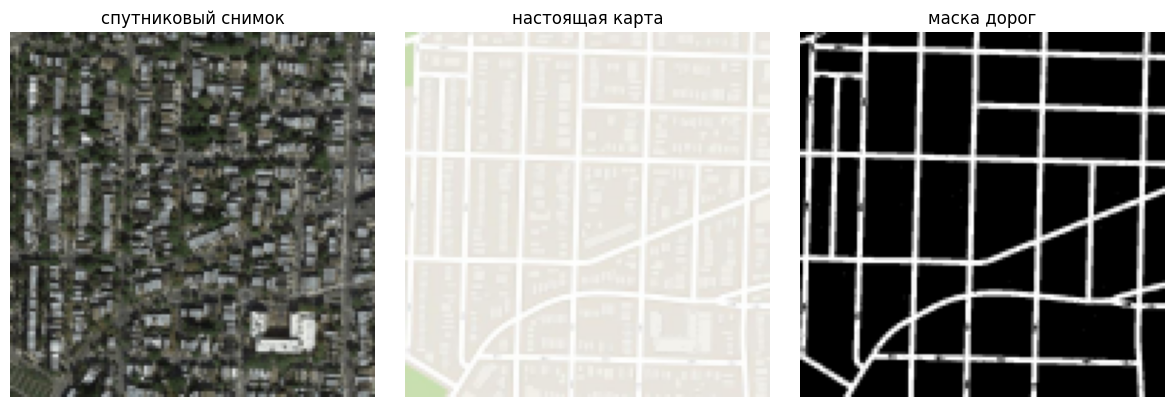

доля дорожных пикселей 0.18


In [3]:
def read_pair(path):
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError("не удалось открыть изображение")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    middle = image.shape[1] // 2
    satellite = image[:, :middle]
    real_map = image[:, middle:]

    road = (real_map.min(axis=2) >= road_threshold).astype(np.uint8)

    satellite = cv2.resize(satellite, (image_size, image_size), interpolation=cv2.INTER_AREA)
    real_map = cv2.resize(real_map, (image_size, image_size), interpolation=cv2.INTER_AREA)
    road = cv2.resize(road.astype(np.float32), (image_size, image_size), interpolation=cv2.INTER_AREA)
    return satellite, real_map, road

satellite, real_map, road = read_pair(train_files[0])

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(satellite)
ax[0].set_title("спутниковый снимок")
ax[1].imshow(real_map)
ax[1].set_title("настоящая карта")
ax[2].imshow(road, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("маска дорог")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()
print("доля дорожных пикселей", round(float(road.mean()), 3))

if not 0.01 < road.mean() < 0.5:
    print("проверь порог выделения дорог")

## набор данных

In [4]:
class map_dataset(Dataset):
    def __init__(self, paths, augment=False):
        self.augment = augment
        self.images = []
        for path in paths:
            self.images.append(read_pair(path))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        satellite, real_map, road = self.images[index]

        if self.augment:
            k = random.randrange(4)
            satellite = np.rot90(satellite, k)
            real_map = np.rot90(real_map, k)
            road = np.rot90(road, k)

            if random.random() < 0.5:
                satellite = np.fliplr(satellite)
                real_map = np.fliplr(real_map)
                road = np.fliplr(road)

        satellite = torch.from_numpy(np.ascontiguousarray(satellite.transpose(2, 0, 1))).float() / 255
        real_map = torch.from_numpy(np.ascontiguousarray(real_map.transpose(2, 0, 1))).float() / 255
        road = torch.from_numpy(np.ascontiguousarray(road[None])).float()
        return satellite, real_map, road

train_data = map_dataset(train_files, augment=True)
val_data = map_dataset(val_files)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)

## нейросеть

In [5]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.GroupNorm(4, out_channels),
        nn.LeakyReLU(0.1),
        nn.Conv2d(out_channels, out_channels, 3, padding=1),
        nn.GroupNorm(4, out_channels),
        nn.LeakyReLU(0.1)
    )


class map_generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(3, 24)
        self.enc2 = conv_block(24, 48)
        self.enc3 = conv_block(48, 96)
        self.center = conv_block(96, 144)

        self.dec3 = conv_block(144 + 96, 96)
        self.dec2 = conv_block(96 + 48, 48)
        self.dec1 = conv_block(48 + 24, 24)

        self.map_head = nn.Conv2d(24, 3, 1)
        self.road_head = nn.Conv2d(24, 1, 1)

    def forward(self, x):
        a = self.enc1(x)
        b = self.enc2(f.avg_pool2d(a, 2))
        c = self.enc3(f.avg_pool2d(b, 2))
        center = self.center(f.avg_pool2d(c, 2))

        x = f.interpolate(center, size=c.shape[-2:], mode="bilinear", align_corners=False)
        x = self.dec3(torch.cat((x, c), dim=1))
        x = f.interpolate(x, size=b.shape[-2:], mode="bilinear", align_corners=False)
        x = self.dec2(torch.cat((x, b), dim=1))
        x = f.interpolate(x, size=a.shape[-2:], mode="bilinear", align_corners=False)
        x = self.dec1(torch.cat((x, a), dim=1))

        background = torch.sigmoid(self.map_head(x))
        road_logits = self.road_head(x)
        road_prob = torch.sigmoid(road_logits)
        generated_map = background * (1 - road_prob) + road_prob
        return generated_map, road_logits


generator = map_generator().to(device)

with torch.no_grad():
    example = torch.zeros(1, 3, image_size, image_size, device=device)
    test_map, test_roads = generator(example)

print("размер карты", tuple(test_map.shape))
print("размер маски дорог", tuple(test_roads.shape))

размер карты (1, 3, 128, 128)
размер маски дорог (1, 1, 128, 128)


## обучение с акцентом на дороги

In [6]:
optimizer = torch.optim.Adam(generator.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=12, gamma=0.6)
road_loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(3.0, device=device))


def dice_loss(logits, target):
    prob = torch.sigmoid(logits)
    intersection = (prob * target).sum(dim=(1, 2, 3))
    total = prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * intersection + 1) / (total + 1)).mean()


def loss_function(generated, road_logits, real_map, road):
    road_area = f.max_pool2d(road, 3, stride=1, padding=1)
    weight = 1 + 7 * road_area
    color_loss = (torch.abs(generated - real_map) * weight).mean()

    mask_loss = road_loss_fn(road_logits, road) + dice_loss(road_logits, road)

    edge_x = torch.abs(
        (generated[:, :, :, 1:] - generated[:, :, :, :-1]) -
        (real_map[:, :, :, 1:] - real_map[:, :, :, :-1])
    ).mean()
    edge_y = torch.abs(
        (generated[:, :, 1:, :] - generated[:, :, :-1, :]) -
        (real_map[:, :, 1:, :] - real_map[:, :, :-1, :])
    ).mean()

    return 4 * color_loss + mask_loss + 0.5 * (edge_x + edge_y)


def check_model():
    generator.eval()
    total_loss = 0.0
    total_l1 = 0.0
    tp = 0.0
    fp = 0.0
    fn = 0.0
    total_images = 0

    with torch.no_grad():
        for x, y, road in val_loader:
            x = x.to(device)
            y = y.to(device)
            road = road.to(device)
            predicted, logits = generator(x)
            loss = loss_function(predicted, logits, y, road)
            total_loss += loss.item() * len(x)
            total_l1 += torch.abs(predicted - y).mean().item() * len(x)

            detected = torch.sigmoid(logits) > 0.5
            actual = road > 0.5
            tp += (detected & actual).sum().item()
            fp += (detected & ~actual).sum().item()
            fn += (~detected & actual).sum().item()
            total_images += len(x)

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1_score = 2 * precision * recall / (precision + recall + 1e-8)
    return total_loss / total_images, total_l1 / total_images, f1_score, precision, recall

In [7]:
history_train = []
history_val = []
history_l1 = []
history_f1 = []

best_score = -float("inf")
best_weights = deepcopy(generator.state_dict())
best_epoch = 0

for epoch in range(epochs):
    generator.train()
    train_loss = 0.0
    total_images = 0

    for x, y, road in train_loader:
        x = x.to(device)
        y = y.to(device)
        road = road.to(device)

        predicted, logits = generator(x)
        loss = loss_function(predicted, logits, y, road)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(x)
        total_images += len(x)

    scheduler.step()
    val_loss, val_l1, val_f1, precision, recall = check_model()

    history_train.append(train_loss / total_images)
    history_val.append(val_loss)
    history_l1.append(val_l1)
    history_f1.append(val_f1)

    score = val_f1 - 0.25 * val_l1
    if score > best_score:
        best_score = score
        best_epoch = epoch + 1
        best_weights = deepcopy(generator.state_dict())

    print(
        "эпоха", epoch + 1,
        "ошибка", round(history_train[-1], 4),
        "проверка", round(val_loss, 4),
        "качество дорог", round(val_f1, 3)
    )

generator.load_state_dict(best_weights)
generator.eval()
print("лучшая эпоха", best_epoch)

эпоха 1 ошибка 2.4185 проверка 2.2291 качество дорог 0.101
эпоха 2 ошибка 2.1579 проверка 2.109 качество дорог 0.009
эпоха 3 ошибка 2.025 проверка 1.9741 качество дорог 0.282
эпоха 4 ошибка 1.937 проверка 1.8988 качество дорог 0.258
эпоха 5 ошибка 1.8502 проверка 1.857 качество дорог 0.372
эпоха 6 ошибка 1.8082 проверка 1.8189 качество дорог 0.349
эпоха 7 ошибка 1.7786 проверка 1.7991 качество дорог 0.362
эпоха 8 ошибка 1.7509 проверка 1.7521 качество дорог 0.405
эпоха 9 ошибка 1.7221 проверка 1.7075 качество дорог 0.429
эпоха 10 ошибка 1.6889 проверка 1.6834 качество дорог 0.448
эпоха 11 ошибка 1.6439 проверка 1.6075 качество дорог 0.484
эпоха 12 ошибка 1.6084 проверка 1.5874 качество дорог 0.495
эпоха 13 ошибка 1.5899 проверка 1.5371 качество дорог 0.516
эпоха 14 ошибка 1.5333 проверка 1.5263 качество дорог 0.514
эпоха 15 ошибка 1.5147 проверка 1.4545 качество дорог 0.556
эпоха 16 ошибка 1.4796 проверка 1.4179 качество дорог 0.573
эпоха 17 ошибка 1.4592 проверка 1.3815 качество дорог

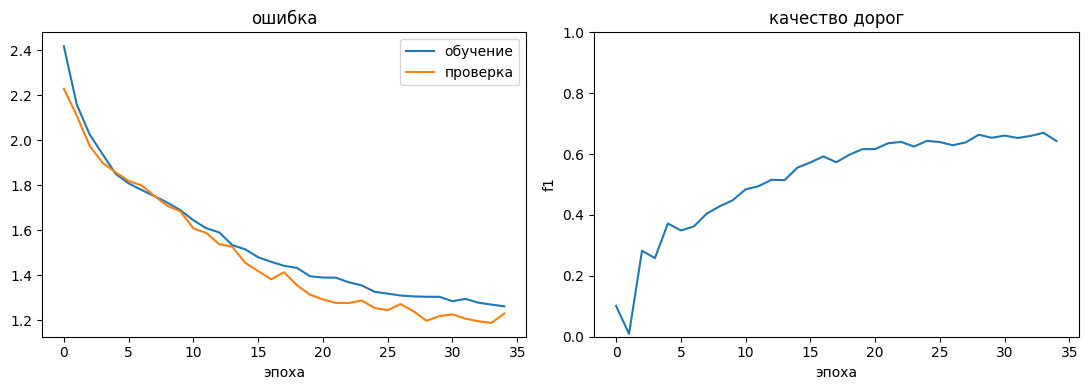

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history_train, label="обучение")
ax[0].plot(history_val, label="проверка")
ax[0].set_title("ошибка")
ax[0].set_xlabel("эпоха")
ax[0].legend()

ax[1].plot(history_f1)
ax[1].set_title("качество дорог")
ax[1].set_xlabel("эпоха")
ax[1].set_ylabel("f1")
ax[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

## результаты

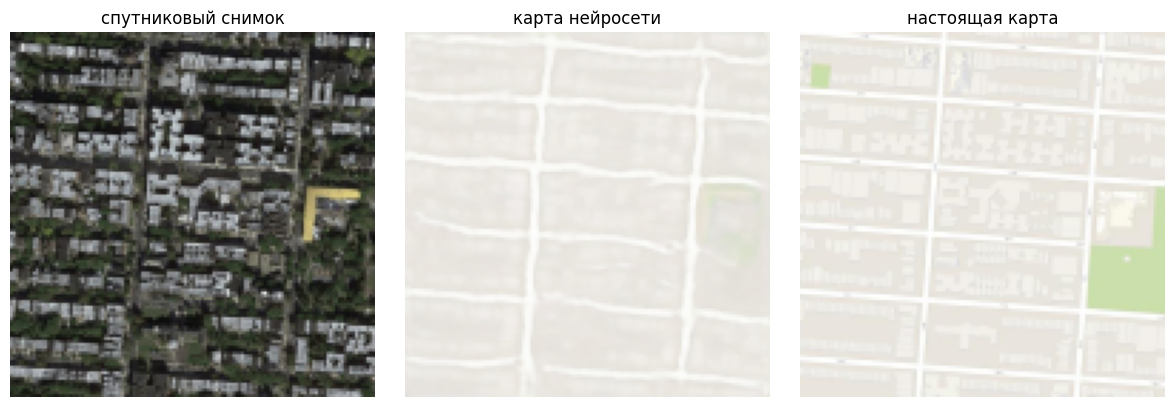

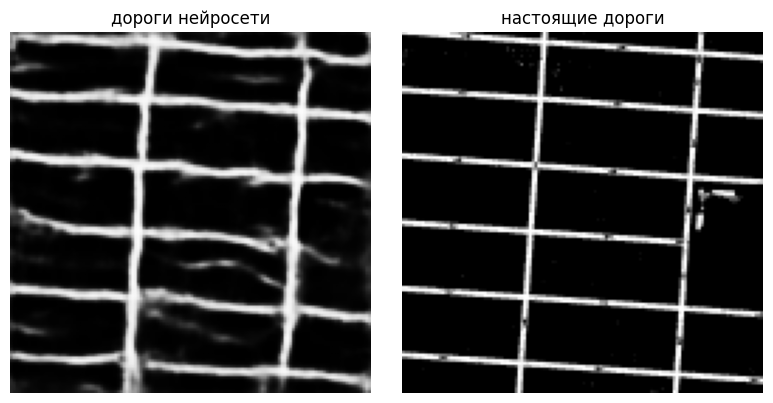

In [9]:
def make_image(tensor):
    image = tensor.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()
    return np.clip(image * 255, 0, 255).astype(np.uint8)


def predict_image(source):
    image = cv2.resize(source, (image_size, image_size), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float()
    x = (x / 255).unsqueeze(0).to(device)

    generator.eval()
    with torch.no_grad():
        result, logits = generator(x)
    color_map = make_image(result)
    road_prob = torch.sigmoid(logits)[0, 0].cpu().numpy()
    return color_map, road_prob


index = 0
satellite, real_map, actual_road = read_pair(val_files[index])
created_map, created_roads = predict_image(satellite)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(satellite)
ax[0].set_title("спутниковый снимок")
ax[1].imshow(created_map)
ax[1].set_title("карта нейросети")
ax[2].imshow(real_map)
ax[2].set_title("настоящая карта")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(created_roads, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("дороги нейросети")
ax[1].imshow(actual_road, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("настоящие дороги")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

In [10]:
val_loss, val_l1, val_f1, precision, recall = check_model()
print("ошибка карты", round(val_l1, 4))
print("точность дорог", round(precision, 3))
print("полнота дорог", round(recall, 3))
print("качество дорог f1", round(val_f1, 3))

if val_f1 < 0.15:
    print("дороги пока определяются плохо, стоит проверить маски и продолжить настройку")

ошибка карты 0.0241
точность дорог 0.586
полнота дорог 0.782
качество дорог f1 0.67


## сохранение

In [11]:
def save_image(name, image):
    cv2.imwrite(str(result_dir / name), cv2.cvtColor(image, cv2.COLOR_RGB2BGR))


save_image("satellite.png", satellite)
save_image("generated_map.png", created_map)
save_image("real_map.png", real_map)
save_image("comparison.png", np.concatenate((satellite, created_map, real_map), axis=1))

cv2.imwrite(str(result_dir / "predicted_roads.png"), (created_roads * 255).astype(np.uint8))
cv2.imwrite(str(result_dir / "real_roads.png"), (actual_road * 255).astype(np.uint8))

torch.save(generator.state_dict(), result_dir / "generator_roads.pth")

## свой снимок

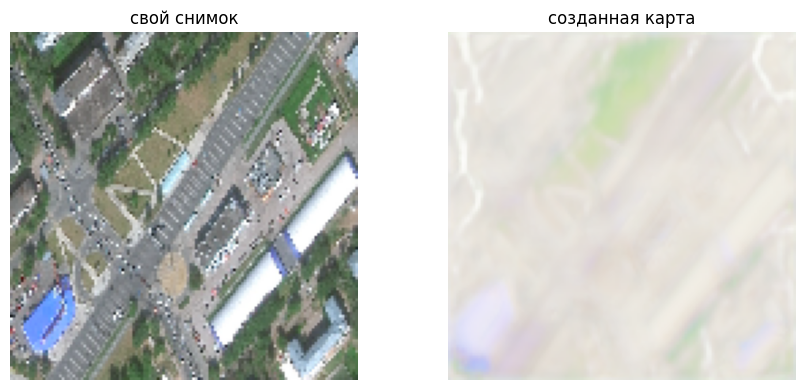

In [12]:
custom_path = None
for name in ("satellite.jpg", "satellite.png", "satellite.bmp"):
    if Path(name).exists():
        custom_path = Path(name)
        break

if custom_path is None:
    print("свой снимок не найден")
else:
    custom = cv2.imread(str(custom_path))
    if custom is None:
        raise ValueError("не удалось открыть свой снимок")
    custom = cv2.cvtColor(custom, cv2.COLOR_BGR2RGB)
    own_map, own_roads = predict_image(custom)
    save_image("own_map.png", own_map)

    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    ax[0].imshow(cv2.resize(custom, (image_size, image_size)))
    ax[0].set_title("свой снимок")
    ax[1].imshow(own_map)
    ax[1].set_title("созданная карта")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()